# Steinhart and Hart Equation Curve Fit

## Solving for the coefficients of the Stienhart-Hart Equation 

$$ \frac{1}{T} = A + Bln(R) + C[ln(R)]^2 + D[ln(R)]^3 $$



- https://en.wikipedia.org/wiki/Steinhart%E2%80%93Hart_equation
- https://northstarsensors.com/calculating-temperature-from-resistance

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [2]:
# NTCLE100E3103 (10 kOhm @ 25 C, B25/85 = 3977 K) resistance-temperature data
# Source: Vishay NTCLE100E3 datasheet, Doc No. 29049

T_C = np.array([
    -40, -35, -30, -25, -20, -15, -10, -5, 0, 5,
    10, 15, 20, 25, 30, 35, 40, 45, 50, 55,
    60, 65, 70, 75, 80, 85, 90, 95, 100, 105,
    110, 115, 120, 125, 130, 135, 140, 145, 150
])

R_T = np.array([
    332094, 239900, 175200, 129287, 96358, 72500, 55046, 42157, 32554, 25339,
    19872, 15698, 12488, 10000, 8059, 6535, 5330, 4372, 3605, 2989,
    2490, 2084, 1753, 1481, 1256, 1070, 915.4, 786.0, 677.3, 585.7,
    508.3, 442.6, 386.6, 338.7, 297.7, 262.4, 231.9, 205.5, 182.6
])

In [3]:
# --- Extended Steinhart-Hart curve fit (4 terms) using scipy ---

T_K = T_C + 273.15          # convert to Kelvin (SI)
y = 1.0 / T_K                 # target: 1/T
lnR = np.log(R_T)             # ln(R)

def steinhart_hart(lnR, A, B, C, D):
    return A + B*lnR + C*lnR**2 + D*lnR**3

In [4]:
# Initial guess (rough order-of-magnitude values help convergence)
p0 = [1e-3, 1e-4, 1e-6, 1e-7]

coeffs, cov = curve_fit(steinhart_hart, lnR, y, p0=p0)
A, B, C, D = coeffs

# Standard errors on each coefficient (from the covariance matrix)
perr = np.sqrt(np.diag(cov))


# --- Check fit quality ---
T_K_fit = 1.0 / steinhart_hart(lnR, A, B, C, D)
T_C_fit = T_K_fit - 273.15

max_err = np.max(np.abs(T_C_fit - T_C))
rmse = np.sqrt(np.mean((T_C_fit - T_C)**2))

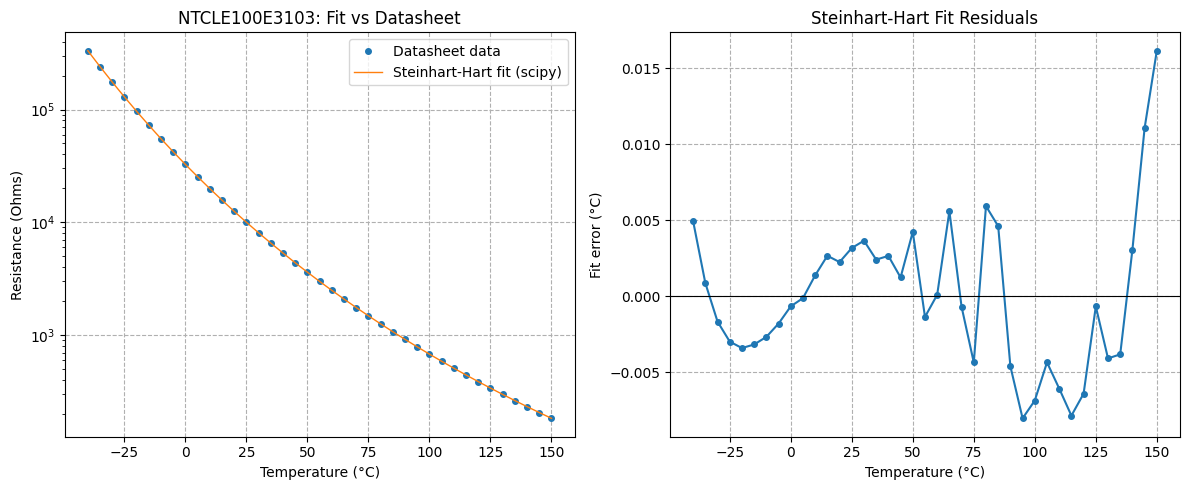

A = 1.157308e-03
B = 2.257625e-04
C = 7.649140e-07
D = 6.711181e-08
Std errors: A:4.97e-07  B:1.80e-07  C:2.10e-08  D:7.91e-10

Max error: 0.0161 C
RMSE:      0.0050 C


In [5]:
# --- Side-by-side plots: fit vs data, and residuals ---
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left: fit vs data
axes[0].plot(T_C, R_T, 'o', label='Datasheet data', markersize=4)
axes[0].plot(T_C_fit, R_T, '-', label='Steinhart-Hart fit (scipy)', linewidth=1)
axes[0].legend()
axes[0].set_xlabel('Temperature (°C)')
axes[0].set_ylabel('Resistance (Ohms)')
axes[0].set_yscale('log')
axes[0].set_title('NTCLE100E3103: Fit vs Datasheet')
axes[0].grid(ls='--')

# Right: residuals
axes[1].plot(T_C, T_C_fit - T_C, 'o-', markersize=4)
axes[1].axhline(0, color='k', linewidth=0.8)
axes[1].set_xlabel('Temperature (°C)')
axes[1].set_ylabel('Fit error (°C)')
axes[1].set_title('Steinhart-Hart Fit Residuals')
axes[1].grid(ls='--')

plt.tight_layout()
plt.show()


print(f"A = {A:.6e}")
print(f"B = {B:.6e}")
print(f"C = {C:.6e}")
print(f"D = {D:.6e}")
print(f"Std errors: A:{perr[0]:.2e}  B:{perr[1]:.2e}  C:{perr[2]:.2e}  D:{perr[3]:.2e}")

print(f"\nMax error: {max_err:.4f} C")
print(f"RMSE:      {rmse:.4f} C")